## 1. Install and import packages

In [19]:
%pip install cobra networkx pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [37]:
from pathlib import Path
import re
import urllib.request
import cobra
from cobra.io import read_sbml_model
from cobra.util.array import create_stoichiometric_matrix
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

## 2. Download and import the SBML model

In [38]:
SBML_PATH = Path("/Users/kerengachogu/Downloads/iMM904.xml")        # file in the notebook folder
# SBML_PATH = Path(r"C:\Users\ali\Downloads\.....xml") 

model = read_sbml_model(str(SBML_PATH))
print(model)

iMM904


## 3. Basic model exploration helpers

In [14]:
#model
#model.metabolites[1]
#print(len(modell.reactions))

In [40]:
def metabolites_table(model):
    return pd.DataFrame([{
        "id": m.id, "name": m.name, "compartment": m.compartment,
        "formula": m.formula, "charge": m.charge
    } for m in model.metabolites]).set_index("id")


display(metabolites_table(model).head(5))

,name,compartment,formula,charge
id,,,,
2dr5p_c,2-Deoxy-D-ribose 5-phosphate,c,C5H9O7P,-2
2hb_c,2 Hydroxybutyrate C4H7O3,c,C4H7O3,-1
2hb_e,2 Hydroxybutyrate C4H7O3,e,C4H7O3,-1
2hhxdal_c,2 Hydroxy hexadecanal C16H32O2,c,C16H32O2,0
2hp6mbq_m,2 Hexaprenyl 6 methoxy 1 4 benzoquinone C37H54O3,m,C37H54O3,0


## 4. Stoichiometric matrix

In [44]:
S = create_stoichiometric_matrix(model, array_type="DataFrame")
print("Stoichiometric matrix (metabolites × reactions):", S.shape)
display(S.iloc[:1, :1])

Stoichiometric matrix (metabolites × reactions): (1226, 1577)


,CITtcp
2dr5p_c,0.0


## 5. E & P matrices

In [45]:
MERGE_COMPARTMENTS = False      

S = create_stoichiometric_matrix(model, array_type="DataFrame")
lb = np.array([r.lower_bound for r in model.reactions])        # lower flux bounds 
ub = np.array([r.upper_bound for r in model.reactions])        # upper flux bounds
reversible = (lb < 0) & (ub > 0)                               # can run in both directions
backward   = (lb < 0) & (ub <= 0)                              # can only run against the written direction

if MERGE_COMPARTMENTS:
    base = S.index.str.rsplit("_", n=1).str[0]                 # "atp_c" -> "atp"
    S = S.groupby(base).sum()                                  # add up rows of the same compound
Sv = S.values.copy()
Sv[:, backward] *= -1                                          # flip so written direction = real direction
print(f"S: {S.shape[0]} substrates x {S.shape[1]} reactions | reversible: {reversible.sum()}")

# 1. Educt matrix E and product matrix P (0/1, substrates x reactions)

pos, neg = Sv > 0, Sv < 0                                      # produced / consumed
E = neg | (pos & reversible)                                   # educt: consumed, or any member of a reversible reaction
P = pos | (neg & reversible)                                   # product: produced, or any member of a reversible reaction

S: 1226 substrates x 1577 reactions | reversible: 495


In [46]:
# 2. Directed adjacency matrix
A = (E.astype(int) @ P.astype(int).T) > 0                         # entry (i,j): is there a reaction that consumes i and produces j?  (matrix product over the reaction axis)
A = A.astype(int)                                                 # True/False -> 1/0
np.fill_diagonal(A, 0)                                            # remove self-loops (i -> i)
A = pd.DataFrame(A, index=S.index, columns=S.index)               # put the substrate names back as row and column labels
print("A:", A.shape, "| directed edges:", int(A.values.sum()))    # size of A and number of 1s = number of edges

# 3. Degrees from A
kin  = A.values.sum(axis=0)                                       # column sum: how many different substrates point TO this one
kout = A.values.sum(axis=1)                                       # row sum: how many different substrates this one points TO
A_und = ((A.values + A.values.T) > 0).astype(int)                 # undirected: a link exists if i->j or j->i (symmetric matrix)
kall = A_und.sum(axis=1)                                          # number of different neighbours, direction ignored
deg = pd.DataFrame({"kin": kin, "kout": kout, "kall": kall}, index=S.index)   # one table, one row per substrate
#display(deg.describe().loc[["mean", "max"]].round(2))             # average and largest degree
display(deg.sort_values("kall", ascending=False).head(8))         # the biggest hubs

A: (1226, 1226) | directed edges: 7377


,kin,kout,kall
h_c,453,345,525
h2o_c,146,220,253
atp_c,73,164,165
pi_c,157,62,159
h_m,114,123,151
adp_c,138,60,142
h_e,97,118,132
ppi_c,112,35,113


Note: you may need to restart the kernel to use updated packages.
Calculating best minimal value for power law fit


Fitting xmin: 100%|████████████████████████████| 48/48 [00:00<00:00, 826.63it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|███████████████████████████| 46/46 [00:00<00:00, 1116.62it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|███████████████████████████| 59/59 [00:00<00:00, 1166.11it/s]


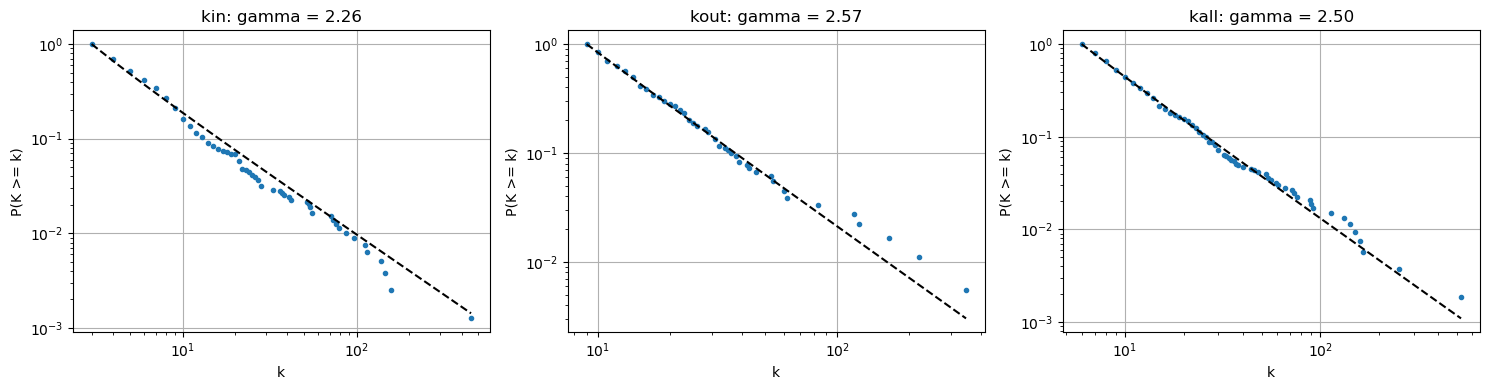

In [50]:
%pip install powerlaw
import powerlaw

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["kin", "kout", "kall"]):
    data = deg[name][deg[name] > 0].values
    fit = powerlaw.Fit(data, discrete=True)
    fit.plot_ccdf(ax=ax, marker=".", linestyle="")
    fit.power_law.plot_ccdf(ax=ax, linestyle="--", color="k")
    ax.set_title(f"{name}: gamma = {fit.alpha:.2f}")
    ax.set_xlabel("k")
    ax.set_ylabel("P(K >= k)")
plt.tight_layout()
plt.show()

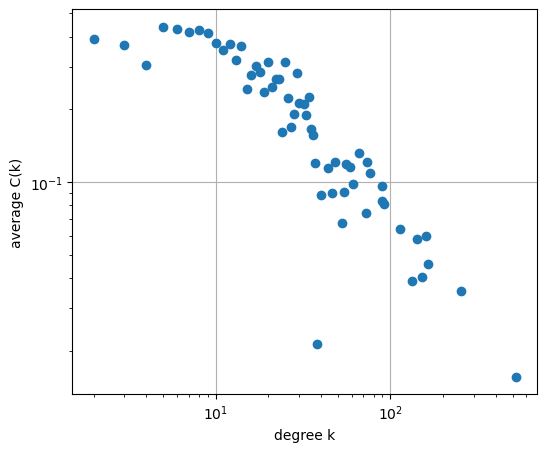

In [53]:
G = nx.from_numpy_array(A_und)
C = pd.Series(nx.clustering(G))
ck = pd.DataFrame({"k": kall, "C": C}).query("k > 1").groupby("k")["C"].mean()
ax = ck[ck > 0].plot(loglog=True, marker="o", linestyle="", figsize=(6, 5))
ax.set_xlabel("degree k")
ax.set_ylabel("average C(k)")
plt.show()